# Mock F150W2 photometry from observed spectra

The Baker spectra are read directly from the `SPEC1D` binary tables, while the observed photometry is loaded from local FITS files with `gordian.loading.load_phot_data`. The notebook keeps the photometry in `nJy`, and now also shows the spectra in CGS.


In [ ]:
import numpy as np
import pandas as pd

import smplotlib
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.lines import Line2D

import astropy.units as u
from astropy.io import fits
from IPython.display import display

from gordian.config import PhotConfig
from specconvert import convert_flux, convert_wave
from gordian.loading import load_phot_data
from sedpy.observate import getSED, load_filters


In [98]:
LAPIS_DIR = Path('/Users/Jonah/PhD/Research/lapis')
SPECTRA_DIR = LAPIS_DIR / 'data_external/collaborators/wbaker'
PHOTOMETRY_DIR = LAPIS_DIR / 'data_processed/photometry'

COS_SPEC_PATH = SPECTRA_DIR / 'capers-cos04-v4_prism-clear_6368_44863.spec.fits'
GS_SPEC_PATH = SPECTRA_DIR / 'gds-barrufet-s67-v4_prism-clear_2198_6687.spec.fits'

COS_PHOT_PATH = PHOTOMETRY_DIR / 'cos-z5-q1_wbaker_photometry.fits'
GS_PHOT_PATH = PHOTOMETRY_DIR / 'gs-z5-q1_wbaker_photometry.fits'

lapis_filters_names = {
    "F150W2": "jwst_f150w2",
    "F277W": "jwst_f277w",
    "F444W": "jwst_f444w",
}
lapis_filter_labels = list(lapis_filters_names.keys())
lapis_filter_names = list(lapis_filters_names.values())
filter_name_to_label = {filter_name: filter_label for filter_label, filter_name in lapis_filters_names.items()}
lapis_filter_colors = {
    "F150W2": 'dodgerblue', 
    "F277W": 'darkorange', 
    "F444W": 'crimson'
}
filter_fill_alpha = 0.12
filter_fill_scale = 0.12
flambda_unit = u.erg / (u.s * u.cm**2 * u.AA)
cgs_plot_scale = 1e20

cos_xlim = (0.9, 5.1)
cos_ylim_njy = (0.0, 150)
cos_ylim_cgs = (0.0, 0.4)
gs_xlim = (0.9, 5.1)
gs_ylim_cgs = (0.0, 1.5)
gs_ylim_njy = (0.0, 400)

obs_spec_plot_kwargs = {'where': 'mid', 'color': 'gray', 'lw': 1.2}
obs_spec_legend_kwargs = {'color': 'gray', 'lw': 1.2}

obs_phot_plot_kwargs = {
    'marker': 's',
    'ms': 5.5,
    'mfc': 'white',
    'mec': 'black',
    'ecolor': 'black',
    'elinewidth': 1.0,
    'capsize': 0,
    'ls': 'none',
    'zorder': 4
}

obs_phot_legend_kwargs = {
    'marker': 's',
    'markerfacecolor': 'white',
    'markeredgecolor': 'black',
    'color': 'black',
    'lw': 0
}

syn_phot_plot_kwargs = {
    label: {
        'edgecolor': lapis_filter_colors[label],
        'facecolor': 'white',
        's': 70,
        'linewidth': 1.5,
        'zorder': 5
    }
    for label in lapis_filter_labels
}

syn_phot_legend_kwargs = {
    label: {
        'marker': 'o',
        'markerfacecolor': 'white',
        'markeredgecolor': lapis_filter_colors[label],
        'markeredgewidth': 1.5,
        'color': lapis_filter_colors[label],
        'lw': 0
    }
    for label in lapis_filter_labels
}

legend_handles = [
    Line2D([0], [0], label='Observed spectrum', **obs_spec_legend_kwargs),
    Line2D([0], [0], label='Observed photometry', **obs_phot_legend_kwargs),
    Line2D([0], [0], label='F150W2 synthetic', **syn_phot_legend_kwargs['F150W2']),
    Line2D([0], [0], label='F277W synthetic', **syn_phot_legend_kwargs['F277W']),
    Line2D([0], [0], label='F444W synthetic', **syn_phot_legend_kwargs['F444W']),
]

In [99]:
synthetic_filters = load_filters(lapis_filter_names)
synthetic_filter_pivot_um = convert_wave(np.asarray([filt.wave_pivot for filt in synthetic_filters], dtype=float), u.AA, u.um)

def add_lapis_filter_curves(ax, *filter_names):
    """Add filled sedpy filter curves to a spectrum axis."""

    if len(filter_names) == 0:
        filter_names = lapis_filter_names

    filter_fill_scale_plot = filter_fill_scale * ax.get_ylim()[1]
    sedpy_filters = load_filters(filter_names)

    for filter_name, sedpy_filter in zip(filter_names, sedpy_filters):
        filter_label = filter_name_to_label[filter_name]
        filter_wave_um = convert_wave(np.asarray(sedpy_filter.wavelength, dtype=float), u.AA, u.um)
        filter_trans = np.asarray(sedpy_filter.transmission, dtype=float)
        filter_trans = filter_trans / np.nanmax(filter_trans)

        ax.plot(filter_wave_um, filter_fill_scale_plot * filter_trans, color=lapis_filter_colors[filter_label], lw=1.0, zorder=2)

        ax.fill_between(filter_wave_um, 0, filter_fill_scale_plot * filter_trans, color=lapis_filter_colors[filter_label], alpha=filter_fill_alpha, lw=0, zorder=1)

def convert_flux_to_cgs_plot(flux_in, wave_um, in_unit, err_in=None):
    """Convert flux values to the CGS plotting scale."""

    flux_cgs, err_cgs = convert_flux(flux_in, in_unit, flambda_unit, err=err_in, wave=np.asarray(wave_um, dtype=float) * u.um)
    flux_plot = cgs_plot_scale * flux_cgs
    err_plot = None if err_cgs is None else cgs_plot_scale * err_cgs
    return flux_plot, err_plot


cos_phot_config = PhotConfig(
    data_dir=str(COS_PHOT_PATH.parent),
    data_file=COS_PHOT_PATH.name,
    filter_prefix=None,
    mask_col='VALID',
    in_unit=u.nJy,
    out_unit=u.nJy,
    in_wave_unit=u.um,
    out_wave_unit=u.um,
)
cos_sedpy_filters, cos_waveff_um, cos_flux_njy, cos_err_njy, cos_phot_ok, cos_filter_names = load_phot_data(cos_phot_config)
cos_pivot_um = convert_wave(np.asarray([filt.wave_pivot for filt in cos_sedpy_filters], dtype=float), u.AA, u.um)
cos_effective_um = convert_wave(np.asarray([filt.wave_effective for filt in cos_sedpy_filters], dtype=float), u.AA, u.um)

cos_phot_df = pd.DataFrame({
    'filter': cos_filter_names,
    'waveff_um': cos_waveff_um,
    'pivot_um': cos_pivot_um,
    'flux_njy': cos_flux_njy,
    'err_njy': cos_err_njy,
    'valid': cos_phot_ok,
})
display(cos_phot_df.round({'waveff_um': 4, 'pivot_um': 4, 'flux_njy': 1, 'err_njy': 1}))


,filter,waveff_um,pivot_um,flux_njy,err_njy,valid
0,jwst_f090w,0.8983,0.9024,-13.0,16.0,True
1,jwst_f115w,1.1486,1.1541,-10.2,7.5,True
2,jwst_f150w,1.4944,1.5009,15.1,6.5,True
3,jwst_f200w,1.9782,1.9876,21.4,6.0,True
4,jwst_f277w,2.7605,2.7762,78.3,7.8,True
5,jwst_f356w,3.5484,3.5655,89.8,9.0,True
6,jwst_f410m,4.0787,4.0830,93.0,11.0,True
7,jwst_f444w,4.3787,4.4017,110.0,11.0,True
8,jwst_f560w,5.6152,5.6353,NaN,NaN,False
9,jwst_f770w,7.5911,7.6393,27.0,140.0,True


In [100]:
gs_phot_config = PhotConfig(
    data_dir=str(GS_PHOT_PATH.parent),
    data_file=GS_PHOT_PATH.name,
    filter_prefix=None,
    mask_col='VALID',
    in_unit=u.nJy,
    out_unit=u.nJy,
    in_wave_unit=u.um,
    out_wave_unit=u.um,
)
gs_sedpy_filters, gs_waveff_um, gs_flux_njy, gs_err_njy, gs_phot_ok, gs_filter_names = load_phot_data(gs_phot_config)
gs_pivot_um = convert_wave(np.asarray([filt.wave_pivot for filt in gs_sedpy_filters], dtype=float), u.AA, u.um)
gs_effective_um = convert_wave(np.asarray([filt.wave_effective for filt in gs_sedpy_filters], dtype=float), u.AA, u.um)

gs_phot_df = pd.DataFrame({
    'filter': gs_filter_names,
    'waveff_um': gs_waveff_um,
    'pivot_um': gs_pivot_um,
    'flux_njy': gs_flux_njy,
    'err_njy': gs_err_njy,
    'valid': gs_phot_ok,
})
display(gs_phot_df.round({'waveff_um': 4, 'pivot_um': 4, 'flux_njy': 1, 'err_njy': 1}))


,filter,waveff_um,pivot_um,flux_njy,err_njy,valid
0,jwst_f090w,0.8983,0.9024,12.6,2.9,True
1,jwst_f115w,1.1486,1.1541,25.4,2.7,True
2,jwst_f150w,1.4944,1.5009,29.5,3.0,True
3,jwst_f200w,1.9782,1.9876,52.2,5.2,True
4,jwst_f277w,2.7605,2.7762,134.0,13.0,True
5,jwst_f356w,3.5484,3.5655,162.0,16.0,True
6,jwst_f410m,4.0787,4.0830,190.0,19.0,True
7,jwst_f444w,4.3787,4.4017,181.0,18.0,True
8,jwst_f560w,5.6152,5.6353,272.0,46.0,True
9,jwst_f770w,7.5911,7.6393,173.0,47.0,True


In [101]:
with fits.open(COS_SPEC_PATH) as hdul:
    cos_header = hdul['SPEC1D'].header.copy()
    cos_spec = hdul['SPEC1D'].data
    cos_slit = hdul['SLITS'].data[0]

cos_ok = np.isfinite(cos_spec['wave']) & np.isfinite(cos_spec['flux']) & np.isfinite(cos_spec['err'])
cos_spec_wave_um = np.asarray(cos_spec['wave'][cos_ok])
cos_spec_flux_ujy = np.asarray(cos_spec['flux'][cos_ok])
cos_spec_err_ujy = np.asarray(cos_spec['err'][cos_ok])
cos_spec_flux_njy, cos_spec_err_njy = convert_flux(cos_spec_flux_ujy, u.uJy, u.nJy, err=cos_spec_err_ujy)

cos_spec_wave_aa = convert_wave(cos_spec_wave_um, u.um, u.AA)
cos_spec_flux_cgs_aa, cos_spec_err_cgs_aa = convert_flux(cos_spec_flux_ujy, u.uJy, flambda_unit, err=cos_spec_err_ujy, wave=cos_spec_wave_um * u.um)
cos_abmag = np.asarray(getSED(cos_spec_wave_aa, cos_spec_flux_cgs_aa, synthetic_filters))
cos_synth_pivot_um = synthetic_filter_pivot_um.copy()
cos_synth_flux_njy, _ = convert_flux(cos_abmag, u.ABmag, u.nJy, wave=cos_synth_pivot_um * u.um)

cos_header_summary = pd.DataFrame([{
    'filename': COS_SPEC_PATH.name,
    'source_label': 'COS-z5-Q1',
    'source_key': str(cos_slit['source_name']),
    'source_id': int(cos_slit['source_id']),
    'wave_min_um': cos_spec_wave_um.min(),
    'wave_max_um': cos_spec_wave_um.max(),
    'extname': cos_header.get('EXTNAME'),
    'wave_column': cos_header.get('TTYPE1'),
    'wave_unit': cos_header.get('TUNIT1'),
    'flux_column': cos_header.get('TTYPE2'),
    'flux_unit': cos_header.get('TUNIT2'),
    'err_column': cos_header.get('TTYPE3'),
    'err_unit': cos_header.get('TUNIT3'),
    'bunit': cos_header.get('BUNIT'),
}])
cos_synth_df = pd.DataFrame({
    'filter': lapis_filter_labels,
    'pivot_um': cos_synth_pivot_um,
    'ab_mag': cos_abmag,
    'flux_njy': cos_synth_flux_njy,
})

display(cos_header_summary)
display(cos_synth_df.round({'pivot_um': 4, 'ab_mag': 3, 'flux_njy': 1}))


,filename,source_label,source_key,source_id,wave_min_um,wave_max_um,extname,wave_column,wave_unit,flux_column,flux_unit,err_column,err_unit,bunit
0,capers-cos04-v4_prism-clear_6368_44863.spec.fits,COS-z5-Q1,6368_44863,44863,0.549126,5.495019,SPEC1D,wave,um,flux,uJy,err,uJy,microJansky


,filter,pivot_um,ab_mag,flux_njy
0,F150W2,1.6718,28.970,9.4
1,F277W,2.7762,27.513,35.9
2,F444W,4.4017,27.348,41.8


In [102]:
with fits.open(GS_SPEC_PATH) as hdul:
    gs_header = hdul['SPEC1D'].header.copy()
    gs_spec = hdul['SPEC1D'].data
    gs_slit = hdul['SLITS'].data[0]

gs_ok = np.isfinite(gs_spec['wave']) & np.isfinite(gs_spec['flux']) & np.isfinite(gs_spec['err'])
gs_spec_wave_um = np.asarray(gs_spec['wave'][gs_ok])
gs_spec_flux_ujy = np.asarray(gs_spec['flux'][gs_ok])
gs_spec_err_ujy = np.asarray(gs_spec['err'][gs_ok])
gs_spec_flux_njy, gs_spec_err_njy = convert_flux(gs_spec_flux_ujy, u.uJy, u.nJy, err=gs_spec_err_ujy)

gs_spec_wave_aa = convert_wave(gs_spec_wave_um, u.um, u.AA)
gs_spec_flux_cgs_aa, gs_spec_err_cgs_aa = convert_flux(gs_spec_flux_ujy, u.uJy, flambda_unit, err=gs_spec_err_ujy, wave=gs_spec_wave_um * u.um)
gs_abmag = np.asarray(getSED(gs_spec_wave_aa, gs_spec_flux_cgs_aa, synthetic_filters))
gs_synth_pivot_um = synthetic_filter_pivot_um.copy()
gs_synth_flux_njy, _ = convert_flux(gs_abmag, u.ABmag, u.nJy, wave=gs_synth_pivot_um * u.um)

gs_header_summary = pd.DataFrame([{
    'filename': GS_SPEC_PATH.name,
    'source_label': 'GS-z5-Q1',
    'source_key': str(gs_slit['source_name']),
    'source_id': int(gs_slit['source_id']),
    'wave_min_um': gs_spec_wave_um.min(),
    'wave_max_um': gs_spec_wave_um.max(),
    'extname': gs_header.get('EXTNAME'),
    'wave_column': gs_header.get('TTYPE1'),
    'wave_unit': gs_header.get('TUNIT1'),
    'flux_column': gs_header.get('TTYPE2'),
    'flux_unit': gs_header.get('TUNIT2'),
    'err_column': gs_header.get('TTYPE3'),
    'err_unit': gs_header.get('TUNIT3'),
    'bunit': gs_header.get('BUNIT'),
}])
gs_synth_df = pd.DataFrame({
    'filter': lapis_filter_labels,
    'pivot_um': gs_synth_pivot_um,
    'ab_mag': gs_abmag,
    'flux_njy': gs_synth_flux_njy,
})

display(gs_header_summary)
display(gs_synth_df.round({'pivot_um': 4, 'ab_mag': 3, 'flux_njy': 1}))


,filename,source_label,source_key,source_id,wave_min_um,wave_max_um,extname,wave_column,wave_unit,flux_column,flux_unit,err_column,err_unit,bunit
0,gds-barrufet-s67-v4_prism-clear_2198_6687.spec...,GS-z5-Q1,2198_6687,6687,0.549126,5.501833,SPEC1D,wave,um,flux,uJy,err,uJy,microJansky


,filter,pivot_um,ab_mag,flux_njy
0,F150W2,1.6718,27.452,37.9
1,F277W,2.7762,26.179,122.6
2,F444W,4.4017,26.019,142.1


In [103]:
header_summary_df = pd.concat([cos_header_summary, gs_header_summary], ignore_index=True)
synthetic_photometry_df = pd.concat([
    cos_synth_df.assign(source_label='COS-z5-Q1'),
    gs_synth_df.assign(source_label='GS-z5-Q1'),
], ignore_index=True)

display(header_summary_df)
display(synthetic_photometry_df.round({'pivot_um': 4, 'ab_mag': 3, 'flux_njy': 1}))


,filename,source_label,source_key,source_id,wave_min_um,wave_max_um,extname,wave_column,wave_unit,flux_column,flux_unit,err_column,err_unit,bunit
0,capers-cos04-v4_prism-clear_6368_44863.spec.fits,COS-z5-Q1,6368_44863,44863,0.549126,5.495019,SPEC1D,wave,um,flux,uJy,err,uJy,microJansky
1,gds-barrufet-s67-v4_prism-clear_2198_6687.spec...,GS-z5-Q1,2198_6687,6687,0.549126,5.501833,SPEC1D,wave,um,flux,uJy,err,uJy,microJansky


,filter,pivot_um,ab_mag,flux_njy,source_label
0,F150W2,1.6718,28.970,9.4,COS-z5-Q1
1,F277W,2.7762,27.513,35.9,COS-z5-Q1
2,F444W,4.4017,27.348,41.8,COS-z5-Q1
3,F150W2,1.6718,27.452,37.9,GS-z5-Q1
4,F277W,2.7762,26.179,122.6,GS-z5-Q1
5,F444W,4.4017,26.019,142.1,GS-z5-Q1


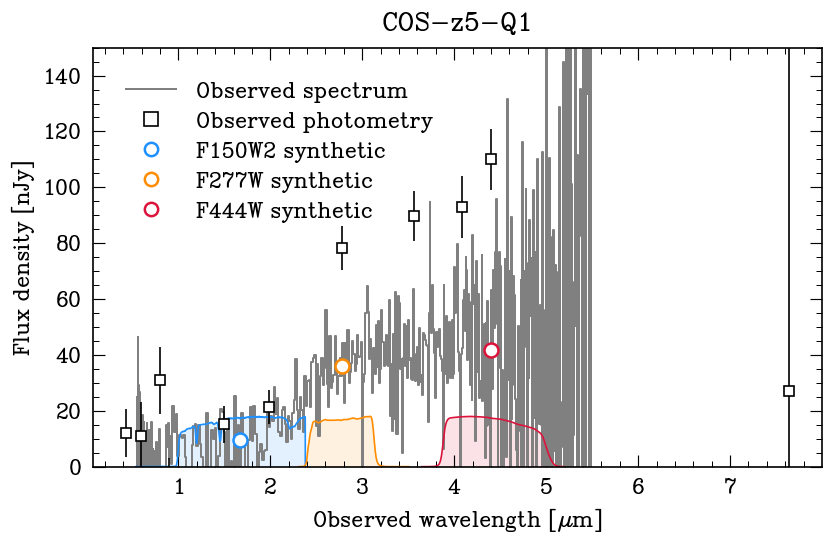

In [104]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))

ax.step(cos_spec_wave_um, cos_spec_flux_njy, label='Observed spectrum', **obs_spec_plot_kwargs)
# ax.fill_between(cos_spec_wave_um, cos_spec_flux_njy - cos_spec_err_njy, cos_spec_flux_njy + cos_spec_err_njy, color='gray', alpha=0.2, lw=0)

ax.errorbar(cos_pivot_um[cos_phot_ok], cos_flux_njy[cos_phot_ok], yerr=cos_err_njy[cos_phot_ok],
            **obs_phot_plot_kwargs)

ax.scatter(cos_synth_pivot_um[0], cos_synth_flux_njy[0], **syn_phot_plot_kwargs['F150W2'])
ax.scatter(cos_synth_pivot_um[1], cos_synth_flux_njy[1], **syn_phot_plot_kwargs['F277W'])
ax.scatter(cos_synth_pivot_um[2], cos_synth_flux_njy[2], **syn_phot_plot_kwargs['F444W'])

ax.set_title('COS-z5-Q1')
ax.set_xlabel(r'Observed wavelength [$\mu$m]')
ax.set_ylabel('Flux density [nJy]')

ax.set_ylim(0, 150)
add_lapis_filter_curves(ax, *lapis_filter_names)

ax.legend(handles=legend_handles, loc='upper left', frameon=False)
plt.tight_layout()


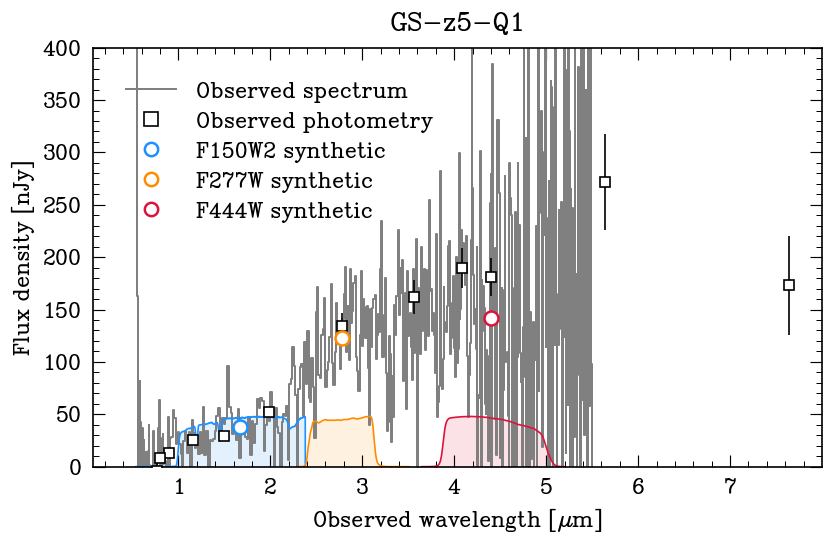

In [105]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.step(gs_spec_wave_um, gs_spec_flux_njy, label='Observed spectrum', **obs_spec_plot_kwargs)
# ax.fill_between(gs_spec_wave_um, gs_spec_flux_njy - gs_spec_err_njy, gs_spec_flux_njy + gs_spec_err_njy, color='gray', alpha=0.2, lw=0)
ax.errorbar(gs_pivot_um[gs_phot_ok], gs_flux_njy[gs_phot_ok], yerr=gs_err_njy[gs_phot_ok],
            **obs_phot_plot_kwargs)
ax.scatter(gs_synth_pivot_um[0], gs_synth_flux_njy[0], **syn_phot_plot_kwargs['F150W2'])
ax.scatter(gs_synth_pivot_um[1], gs_synth_flux_njy[1], **syn_phot_plot_kwargs['F277W'])
ax.scatter(gs_synth_pivot_um[2], gs_synth_flux_njy[2], **syn_phot_plot_kwargs['F444W'])

ax.set_title('GS-z5-Q1')
ax.set_xlabel(r'Observed wavelength [$\mu$m]')
ax.set_ylabel('Flux density [nJy]')

ax.set_ylim(gs_ylim_njy)
add_lapis_filter_curves(ax, *lapis_filter_names)

ax.legend(handles=legend_handles, loc='upper left', frameon=False)
plt.tight_layout()


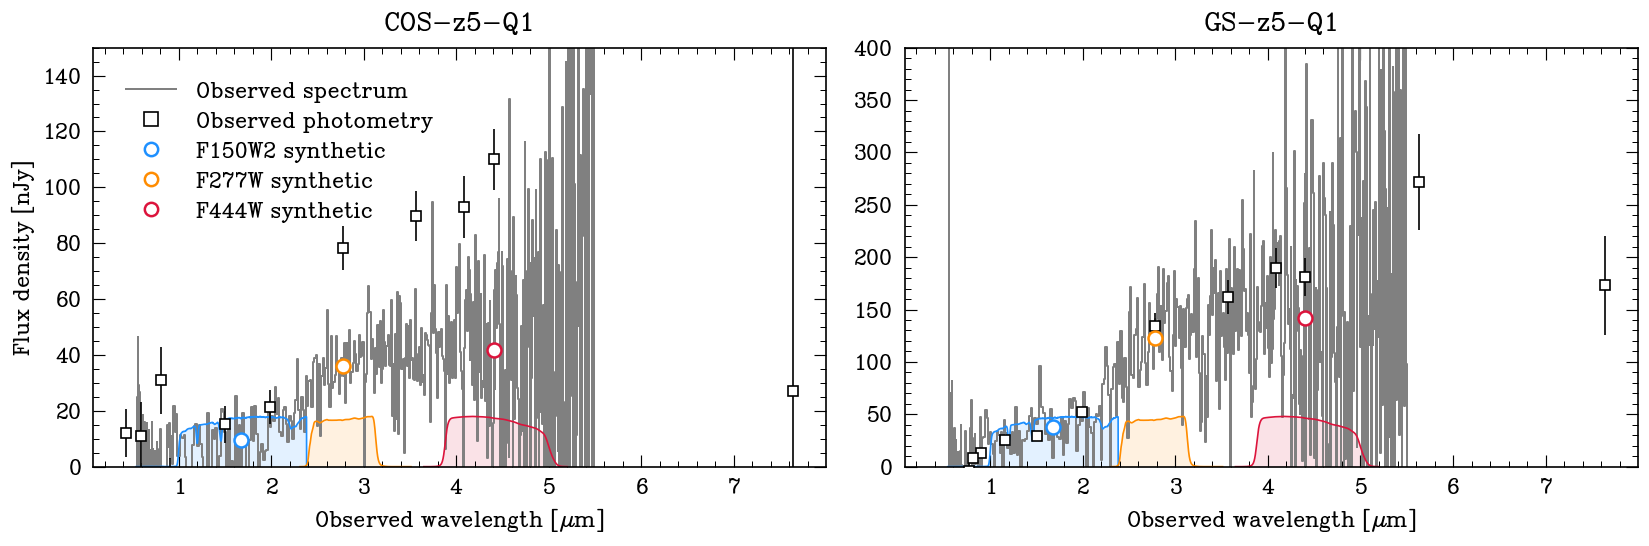

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].step(cos_spec_wave_um, cos_spec_flux_njy, label='Observed spectrum', **obs_spec_plot_kwargs)
# axes[0].fill_between(cos_spec_wave_um, cos_spec_flux_njy - cos_spec_err_njy, cos_spec_flux_njy + cos_spec_err_njy, color='gray', alpha=0.2, lw=0)
axes[0].errorbar(cos_pivot_um[cos_phot_ok], cos_flux_njy[cos_phot_ok], yerr=cos_err_njy[cos_phot_ok],
                 **obs_phot_plot_kwargs)
axes[0].scatter(cos_synth_pivot_um[0], cos_synth_flux_njy[0], **syn_phot_plot_kwargs['F150W2'])
axes[0].scatter(cos_synth_pivot_um[1], cos_synth_flux_njy[1], **syn_phot_plot_kwargs['F277W'])
axes[0].scatter(cos_synth_pivot_um[2], cos_synth_flux_njy[2], **syn_phot_plot_kwargs['F444W'])
axes[0].set_title('COS-z5-Q1')
axes[0].set_xlabel(r'Observed wavelength [$\mu$m]')
axes[0].set_ylabel('Flux density [nJy]')
axes[0].set_ylim(cos_ylim_njy)
add_lapis_filter_curves(axes[0], *lapis_filter_names)

axes[1].step(gs_spec_wave_um, gs_spec_flux_njy, label='Observed spectrum', **obs_spec_plot_kwargs)
# axes[1].fill_between(gs_spec_wave_um, gs_spec_flux_njy - gs_spec_err_njy, gs_spec_flux_njy + gs_spec_err_njy, color='gray', alpha=0.2, lw=0)
axes[1].errorbar(gs_pivot_um[gs_phot_ok], gs_flux_njy[gs_phot_ok], yerr=gs_err_njy[gs_phot_ok],
                 **obs_phot_plot_kwargs)
axes[1].scatter(gs_synth_pivot_um[0], gs_synth_flux_njy[0], **syn_phot_plot_kwargs['F150W2'])
axes[1].scatter(gs_synth_pivot_um[1], gs_synth_flux_njy[1], **syn_phot_plot_kwargs['F277W'])
axes[1].scatter(gs_synth_pivot_um[2], gs_synth_flux_njy[2], **syn_phot_plot_kwargs['F444W'])
axes[1].set_title('GS-z5-Q1')
axes[1].set_xlabel(r'Observed wavelength [$\mu$m]')
axes[1].set_ylim(gs_ylim_njy)
add_lapis_filter_curves(axes[1], *lapis_filter_names)

axes[0].legend(handles=legend_handles, loc='upper left', frameon=False)
plt.tight_layout()


In [107]:
cos_flux_cgs_plot = cgs_plot_scale * cos_spec_flux_cgs_aa
cos_err_cgs_plot = cgs_plot_scale * cos_spec_err_cgs_aa
cos_phot_flux_cgs_plot, cos_phot_err_cgs_plot = convert_flux_to_cgs_plot(cos_flux_njy, cos_pivot_um, u.nJy, err_in=cos_err_njy)
cos_synth_flux_cgs_plot, _ = convert_flux_to_cgs_plot(cos_synth_flux_njy, cos_synth_pivot_um, u.nJy)

gs_flux_cgs_plot = cgs_plot_scale * gs_spec_flux_cgs_aa
gs_err_cgs_plot = cgs_plot_scale * gs_spec_err_cgs_aa
gs_phot_flux_cgs_plot, gs_phot_err_cgs_plot = convert_flux_to_cgs_plot(gs_flux_njy, gs_pivot_um, u.nJy, err_in=gs_err_njy)
gs_synth_flux_cgs_plot, _ = convert_flux_to_cgs_plot(gs_synth_flux_njy, gs_synth_pivot_um, u.nJy)


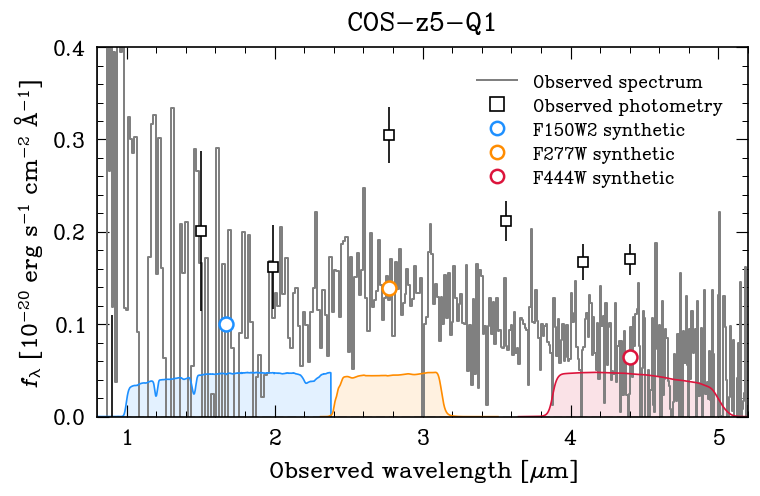

In [108]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.step(cos_spec_wave_um, cos_flux_cgs_plot, label='Observed spectrum', **obs_spec_plot_kwargs)
# ax.fill_between(cos_spec_wave_um, cos_flux_cgs_plot - cos_err_cgs_plot, cos_flux_cgs_plot + cos_err_cgs_plot, color='gray', alpha=0.2, lw=0)

ax.errorbar(cos_pivot_um[cos_phot_ok], cos_phot_flux_cgs_plot[cos_phot_ok], yerr=cos_phot_err_cgs_plot[cos_phot_ok],
            **obs_phot_plot_kwargs)

ax.scatter(cos_synth_pivot_um[0], cos_synth_flux_cgs_plot[0], **syn_phot_plot_kwargs['F150W2'])
ax.scatter(cos_synth_pivot_um[1], cos_synth_flux_cgs_plot[1], **syn_phot_plot_kwargs['F277W'])
ax.scatter(cos_synth_pivot_um[2], cos_synth_flux_cgs_plot[2], **syn_phot_plot_kwargs['F444W'])

ax.set_title('COS-z5-Q1')
ax.set_xlabel(r'Observed wavelength [$\mu$m]', fontsize=16)
ax.set_ylabel(r"$f_\lambda$ [$\rm 10^{-20}\ erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]", fontsize=16)

ax.set_xlim(0.8, 5.2)
ax.set_ylim(cos_ylim_cgs)
ax.axhline(y=0, color='black', linestyle='--', linewidth=0.8)

add_lapis_filter_curves(ax, *lapis_filter_names)

ax.legend(handles=legend_handles, loc='upper right', frameon=False, fontsize=12)


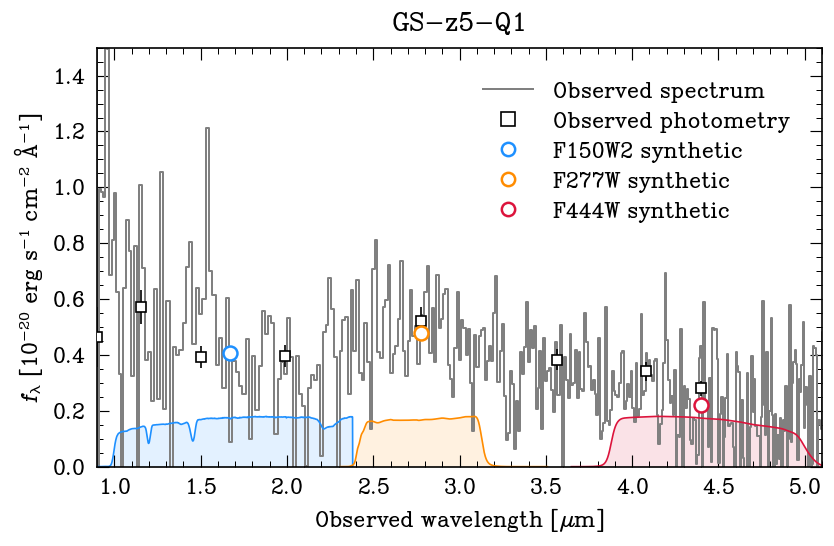

In [109]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.step(gs_spec_wave_um, gs_flux_cgs_plot, label='Observed spectrum', **obs_spec_plot_kwargs)
# ax.fill_between(gs_spec_wave_um, gs_flux_cgs_plot - gs_err_cgs_plot, gs_flux_cgs_plot + gs_err_cgs_plot, color='gray', alpha=0.2, lw=0)
ax.errorbar(gs_pivot_um[gs_phot_ok], gs_phot_flux_cgs_plot[gs_phot_ok], yerr=gs_phot_err_cgs_plot[gs_phot_ok],
            **obs_phot_plot_kwargs)
ax.scatter(gs_synth_pivot_um[0], gs_synth_flux_cgs_plot[0], **syn_phot_plot_kwargs['F150W2'])
ax.scatter(gs_synth_pivot_um[1], gs_synth_flux_cgs_plot[1], **syn_phot_plot_kwargs['F277W'])
ax.scatter(gs_synth_pivot_um[2], gs_synth_flux_cgs_plot[2], **syn_phot_plot_kwargs['F444W'])

ax.set_title('GS-z5-Q1')
ax.set_xlabel(r'Observed wavelength [$\mu$m]')
ax.set_ylabel(r"$f_\lambda$ [$\rm 10^{-20}\ erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]")

ax.set_xlim(gs_xlim)
ax.set_ylim(gs_ylim_cgs)

add_lapis_filter_curves(ax, *lapis_filter_names)
ax.legend(handles=legend_handles, loc='upper right', frameon=False)
plt.tight_layout()


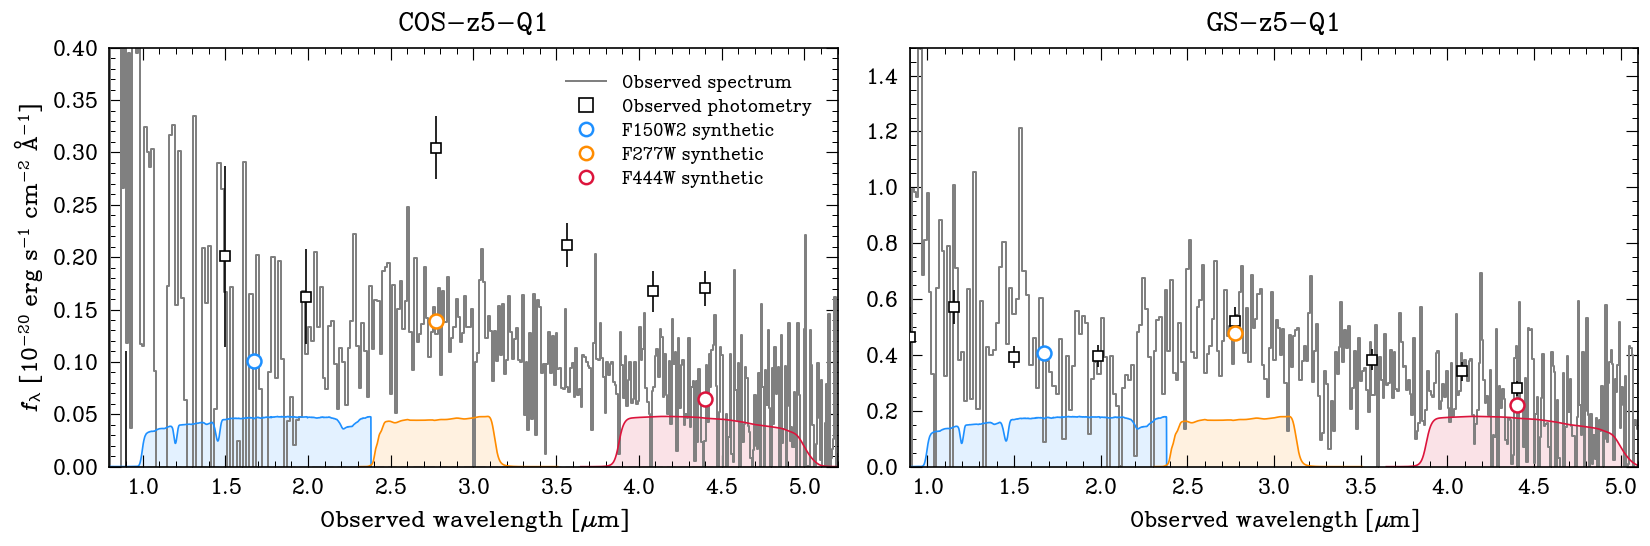

In [110]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].step(cos_spec_wave_um, cos_flux_cgs_plot, label='Observed spectrum', **obs_spec_plot_kwargs)
# axes[0].fill_between(cos_spec_wave_um, cos_flux_cgs_plot - cos_err_cgs_plot, cos_flux_cgs_plot + cos_err_cgs_plot, color='gray', alpha=0.2, lw=0)
axes[0].errorbar(cos_pivot_um[cos_phot_ok], cos_phot_flux_cgs_plot[cos_phot_ok], yerr=cos_phot_err_cgs_plot[cos_phot_ok],
                 **obs_phot_plot_kwargs)
axes[0].scatter(cos_synth_pivot_um[0], cos_synth_flux_cgs_plot[0], **syn_phot_plot_kwargs['F150W2'])
axes[0].scatter(cos_synth_pivot_um[1], cos_synth_flux_cgs_plot[1], **syn_phot_plot_kwargs['F277W'])
axes[0].scatter(cos_synth_pivot_um[2], cos_synth_flux_cgs_plot[2], **syn_phot_plot_kwargs['F444W'])
axes[0].set_title('COS-z5-Q1')
axes[0].set_xlabel(r'Observed wavelength [$\mu$m]', fontsize=16)
axes[0].set_ylabel(r"$f_\lambda$ [$\rm 10^{-20}\ erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]", fontsize=16)
axes[0].set_xlim(0.8, 5.2)
axes[0].set_ylim(cos_ylim_cgs)
axes[0].axhline(y=0, color='black', linestyle='--', linewidth=0.8)
add_lapis_filter_curves(axes[0], *lapis_filter_names)

axes[1].step(gs_spec_wave_um, gs_flux_cgs_plot, label='Observed spectrum', **obs_spec_plot_kwargs)
# axes[1].fill_between(gs_spec_wave_um, gs_flux_cgs_plot - gs_err_cgs_plot, gs_flux_cgs_plot + gs_err_cgs_plot, color='gray', alpha=0.2, lw=0)
axes[1].errorbar(gs_pivot_um[gs_phot_ok], gs_phot_flux_cgs_plot[gs_phot_ok], yerr=gs_phot_err_cgs_plot[gs_phot_ok],
                 **obs_phot_plot_kwargs)
axes[1].scatter(gs_synth_pivot_um[0], gs_synth_flux_cgs_plot[0], **syn_phot_plot_kwargs['F150W2'])
axes[1].scatter(gs_synth_pivot_um[1], gs_synth_flux_cgs_plot[1], **syn_phot_plot_kwargs['F277W'])
axes[1].scatter(gs_synth_pivot_um[2], gs_synth_flux_cgs_plot[2], **syn_phot_plot_kwargs['F444W'])
axes[1].set_title('GS-z5-Q1')
axes[1].set_xlabel(r'Observed wavelength [$\mu$m]')
axes[1].set_xlim(gs_xlim)
axes[1].set_ylim(gs_ylim_cgs)
add_lapis_filter_curves(axes[1], *lapis_filter_names)

axes[0].legend(handles=legend_handles, loc='upper right', frameon=False, fontsize=12)
plt.tight_layout()
